# Лабораторная работа: классификация блюд по признаку здорового питания

**Датасет:** Healthy Eating Dataset  
**Размер:** 2000 наблюдений, 20 столбцов  
**Тип задачи:** бинарная классификация  
**Целевая переменная:** `is_healthy` (0 — блюдо не отмечено как здоровое, 1 — отмечено как здоровое).

## 0. Постановка задачи

Цель работы — построить модель машинного обучения, которая по характеристикам блюда (пищевая ценность, кухня, тип блюда, тип диеты, способ приготовления, время приготовления и рейтинг) предсказывает значение `is_healthy`.

Это задача обучения с учителем: для каждого блюда в датасете уже известна целевая метка. Основной алгоритм — **k ближайших соседей (KNN)**. Он выбран как понятный классификатор, позволяющий исследовать влияние числа соседей `k`. Поскольку алгоритм использует расстояния, числовые признаки необходимо масштабировать, а категориальные — преобразовать в числовой вид.

Для сравнения дополнительно обучим логистическую регрессию и случайный лес. Качество оценим по Accuracy, Precision, Recall, F1-score и матрице ошибок. Тестовая выборка не будет использоваться при подборе гиперпараметров.

## 1. Чтение данных и первичный анализ



In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

DATA_PATH = "healthy_eating_dataset.csv"
df = pd.read_csv(DATA_PATH)

print(f"Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())
print("\nТипы данных:")
display(df.dtypes.to_frame("Тип данных"))
print("\nОсновные статистические характеристики:")
display(df.describe(include="all").T)
print("\nПропуски по столбцам:")
display(df.isna().sum().to_frame("Количество пропусков"))
print("\nКоличество полных дубликатов:", df.duplicated().sum())

Размер датасета: 2000 строк, 20 столбцов


,meal_id,meal_name,cuisine,meal_type,diet_type,calories,protein_g,carbs_g,fat_g,fiber_g,sugar_g,sodium_mg,cholesterol_mg,serving_size_g,cooking_method,prep_time_min,cook_time_min,rating,is_healthy,image_url
0,1,Kid Pasta,Indian,Lunch,Keto,737,52.4,43.9,34.3,16.8,42.9,2079,91,206,Grilled,47,56,4.4,0,https://example.com/images/meal_1.jpg
1,2,Husband Rice,Mexican,Lunch,Paleo,182,74.7,144.4,0.1,22.3,38.6,423,7,317,Roasted,51,34,2.4,0,https://example.com/images/meal_2.jpg
2,3,Activity Rice,Indian,Snack,Paleo,881,52.9,97.3,18.8,20.0,37.5,2383,209,395,Boiled,58,29,4.3,0,https://example.com/images/meal_3.jpg
3,4,Another Salad,Mexican,Snack,Keto,427,17.5,73.1,7.6,9.8,41.7,846,107,499,Grilled,14,81,4.6,0,https://example.com/images/meal_4.jpg
4,5,Quite Stew,Thai,Lunch,Vegan,210,51.6,104.3,26.3,24.8,18.2,1460,42,486,Raw,47,105,4.3,0,https://example.com/images/meal_5.jpg



Типы данных:


,Тип данных
meal_id,int64
meal_name,str
cuisine,str
meal_type,str
diet_type,str
calories,int64
protein_g,float64
carbs_g,float64
fat_g,float64
fiber_g,float64



Основные статистические характеристики:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
meal_id,2000.0,NaN,NaN,NaN,1000.5,577.494589,1.0,500.75,1000.5,1500.25,2000.0
meal_name,2000,1750,Air Stew,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cuisine,2000,8,Indian,282,NaN,NaN,NaN,NaN,NaN,NaN,NaN
meal_type,2000,4,Lunch,513,NaN,NaN,NaN,NaN,NaN,NaN,NaN
diet_type,2000,6,Balanced,352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
calories,2000.0,NaN,NaN,NaN,650.0615,315.419877,100.0,372.0,648.0,914.5,1200.0
protein_g,2000.0,NaN,NaN,NaN,42.86375,21.992887,5.0,23.6,43.6,61.9,79.9
carbs_g,2000.0,NaN,NaN,NaN,75.92425,42.749671,0.0,39.2,75.95,113.025,150.0
fat_g,2000.0,NaN,NaN,NaN,30.0653,17.573243,0.0,14.8,30.3,45.2,60.0
fiber_g,2000.0,NaN,NaN,NaN,15.2458,8.754933,0.0,7.6,15.15,23.2,30.0



Пропуски по столбцам:


,Количество пропусков
meal_id,0
meal_name,0
cuisine,0
meal_type,0
diet_type,0
calories,0
protein_g,0
carbs_g,0
fat_g,0
fiber_g,0



Количество полных дубликатов: 0


## 2. Разделение данных на обучающую и тестовую выборки

Целевой столбец — `is_healthy`. Не используем `meal_id`, `meal_name` и `image_url`: идентификатор и URL являются техническими полями, а название блюда имеет высокую уникальность и может привести к запоминанию отдельных объектов вместо выявления общих закономерностей.

Выделим 25% данных для тестирования. Стратификация сохраняет соотношение классов в обеих выборках.

In [2]:
TARGET = "is_healthy"
if TARGET not in df.columns:
    raise ValueError(f"В датасете отсутствует целевой столбец {TARGET!r}.")

y = df[TARGET].copy()
if y.isna().any():
    raise ValueError("В целевой переменной обнаружены пропуски.")
if y.nunique() != 2:
    raise ValueError(f"Ожидалась бинарная цель, но найдено классов: {y.nunique()}")


y = y.astype(int)

excluded = [c for c in ["meal_id", "meal_name", "image_url", TARGET] if c in df.columns]
X = df.drop(columns=excluded)


extra_excluded = [
    c for c in X.columns
    if c.lower().endswith("_id") or c.lower().endswith("_url")
]
X = X.drop(columns=extra_excluded, errors="ignore")

print("Исключённые столбцы:", excluded + extra_excluded)
print("Используемые признаки:", X.columns.tolist())

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)

for name, part in [("Весь датасет", y), ("Обучающая выборка", y_train), ("Тестовая выборка", y_test)]:
    print(f"\n{name}:")
    display(part.value_counts(normalize=True).sort_index().rename("Доля").to_frame())

Исключённые столбцы: ['meal_id', 'meal_name', 'image_url', 'is_healthy']
Используемые признаки: ['cuisine', 'meal_type', 'diet_type', 'calories', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'sodium_mg', 'cholesterol_mg', 'serving_size_g', 'cooking_method', 'prep_time_min', 'cook_time_min', 'rating']
Обучающая выборка: (1500, 16)
Тестовая выборка: (500, 16)

Весь датасет:


,Доля
is_healthy,
0,0.9065
1,0.0935



Обучающая выборка:


,Доля
is_healthy,
0,0.906667
1,0.093333



Тестовая выборка:


,Доля
is_healthy,
0,0.906
1,0.094


## 3. Визуализация данных и основные характеристики

Изучим баланс классов, распределения числовых и категориальных признаков, а также корреляции числовых переменных.

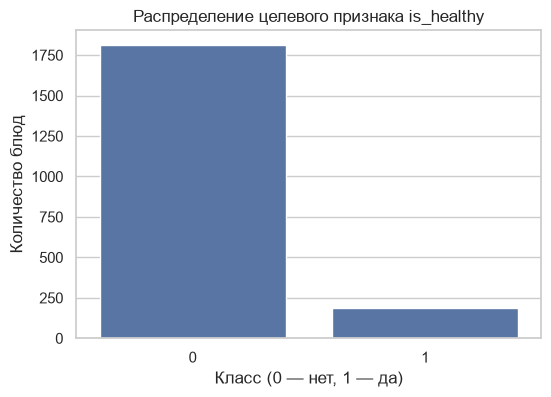

Доля класса 1: 9.3%


In [3]:
plt.figure(figsize=(6, 4))
sns.countplot(x=y, order=sorted(y.unique()))
plt.title("Распределение целевого признака is_healthy")
plt.xlabel("Класс (0 — нет, 1 — да)")
plt.ylabel("Количество блюд")
plt.show()

print("Доля класса 1: {:.1%}".format((y == 1).mean()))

Числовые признаки: ['calories', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'sodium_mg', 'cholesterol_mg', 'serving_size_g', 'prep_time_min', 'cook_time_min', 'rating']
Категориальные признаки: ['cuisine', 'meal_type', 'diet_type', 'cooking_method']
Описательная статистика числовых признаков:


,count,mean,std,min,25%,50%,75%,max
calories,2000.0,650.06,315.42,100.0,372.0,648.00,914.50,1200.0
protein_g,2000.0,42.86,21.99,5.0,23.6,43.60,61.90,79.9
carbs_g,2000.0,75.92,42.75,0.0,39.2,75.95,113.02,150.0
fat_g,2000.0,30.07,17.57,0.0,14.8,30.30,45.20,60.0
fiber_g,2000.0,15.25,8.75,0.0,7.6,15.15,23.20,30.0
sugar_g,2000.0,24.60,14.48,0.0,12.0,24.75,37.20,50.0
sodium_mg,2000.0,1257.32,709.59,50.0,647.5,1273.00,1854.50,2499.0
cholesterol_mg,2000.0,150.46,87.94,0.0,72.0,150.00,228.00,300.0
serving_size_g,2000.0,302.62,115.49,100.0,207.0,302.00,402.00,500.0
prep_time_min,2000.0,33.35,16.48,5.0,19.0,34.00,48.00,60.0


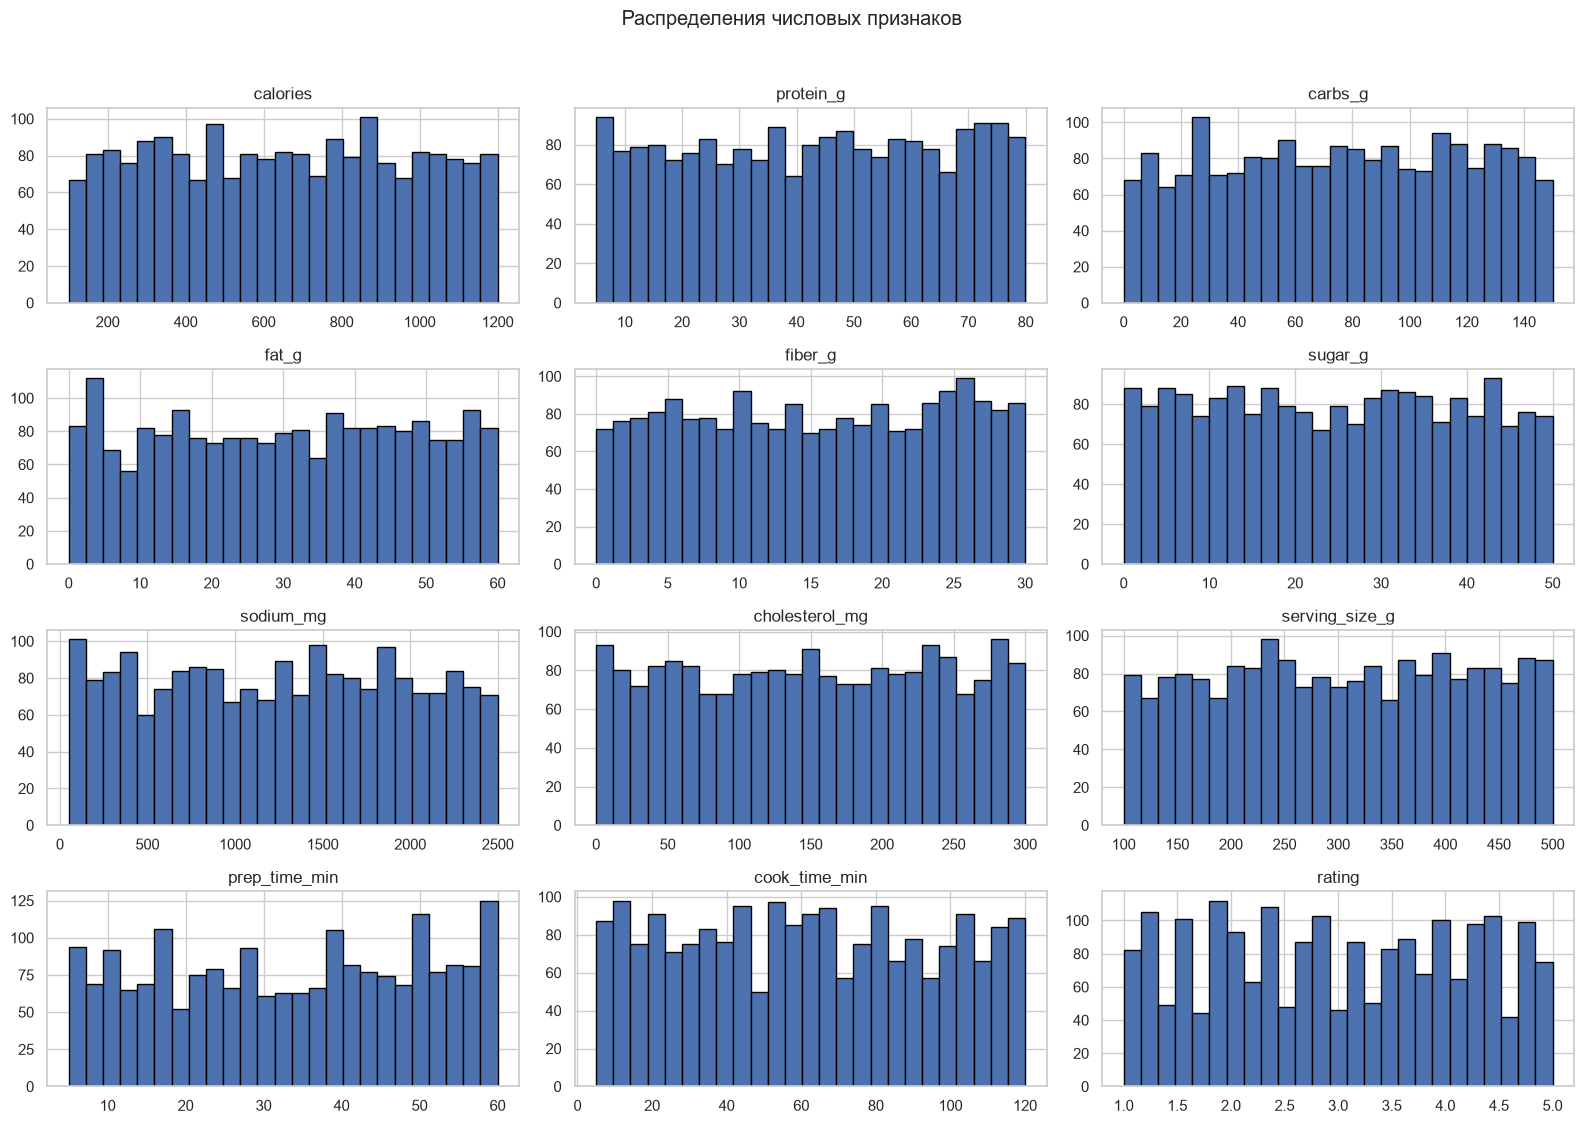

In [4]:
numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = X.select_dtypes(exclude=np.number).columns.tolist()

print("Числовые признаки:", numeric_cols)
print("Категориальные признаки:", categorical_cols)

if numeric_cols:
    print("Описательная статистика числовых признаков:")
    display(X[numeric_cols].describe().T.round(2))

    X[numeric_cols].hist(figsize=(16, 11), bins=25, edgecolor="black")
    plt.suptitle("Распределения числовых признаков", y=1.02)
    plt.tight_layout()
    plt.show()

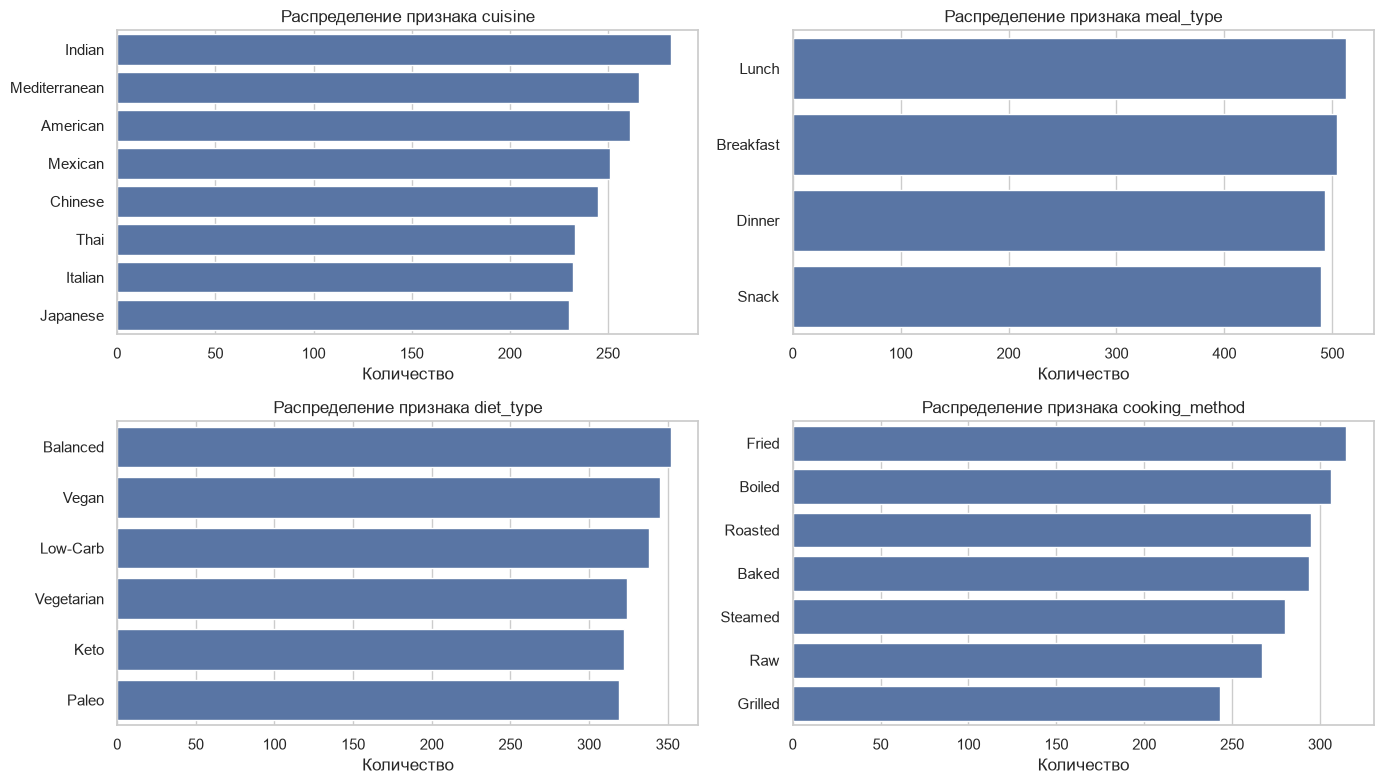

In [5]:
if categorical_cols:
    ncols = 2
    nrows = int(np.ceil(len(categorical_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for col, ax in zip(categorical_cols, axes):
        counts = X[col].astype(str).value_counts()
        sns.barplot(x=counts.values, y=counts.index, ax=ax)
        ax.set_title(f"Распределение признака {col}")
        ax.set_xlabel("Количество")
        ax.set_ylabel("")

    for ax in axes[len(categorical_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

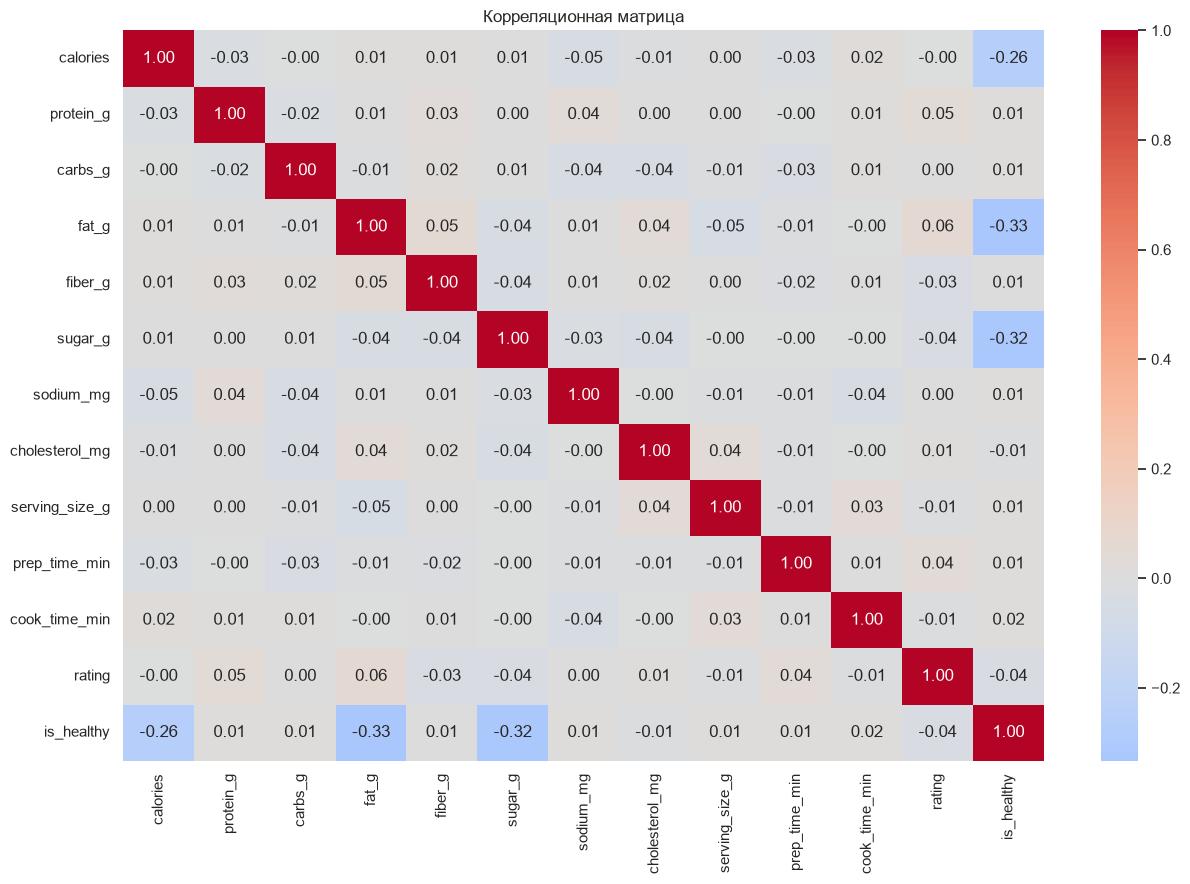

Средние значения числовых признаков в зависимости от класса:


is_healthy,0,1
calories,676.70,391.76
protein_g,42.78,43.71
carbs_g,75.74,77.68
fat_g,31.94,11.85
fiber_g,15.22,15.52
sugar_g,26.08,10.24
sodium_mg,1254.02,1289.30
cholesterol_mg,150.65,148.64
serving_size_g,302.18,306.91
prep_time_min,33.28,34.04


In [6]:
if len(numeric_cols) >= 2:
    corr = df[numeric_cols + [TARGET]].corr(numeric_only=True)
    plt.figure(figsize=(13, 9))
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
    plt.title("Корреляционная матрица")
    plt.tight_layout()
    plt.show()

if numeric_cols:
    print("Средние значения числовых признаков в зависимости от класса:")
    display(df.groupby(TARGET)[numeric_cols].mean().T.round(2))

### Интерпретация результатов визуализации

- Диаграмма целевой переменной показывает, насколько сбалансированы классы. Если один класс встречается значительно чаще, Accuracy может быть недостаточно информативной.
- Гистограммы показывают диапазоны, разброс и форму распределений числовых признаков.
- Корреляционная матрица отражает линейные взаимосвязи. Корреляция не доказывает причинно-следственную связь.
- Сравнение средних значений признаков по классам позволяет предварительно увидеть, какие характеристики могут различаться у здоровых и нездоровых блюд. Окончательно судить о полезности признаков следует по качеству модели на тестовой выборке.

## 4. Анализ выбросов

Для поиска потенциальных выбросов применим правило межквартильного размаха (IQR). Значения ниже `Q1 − 1.5 × IQR` или выше `Q3 + 1.5 × IQR` отмечаются как потенциальные выбросы.

Важно: статистический выброс не обязательно является ошибкой. Например, необычно высокая калорийность может быть реальной характеристикой блюда. Поэтому автоматически удалять такие наблюдения не будем.

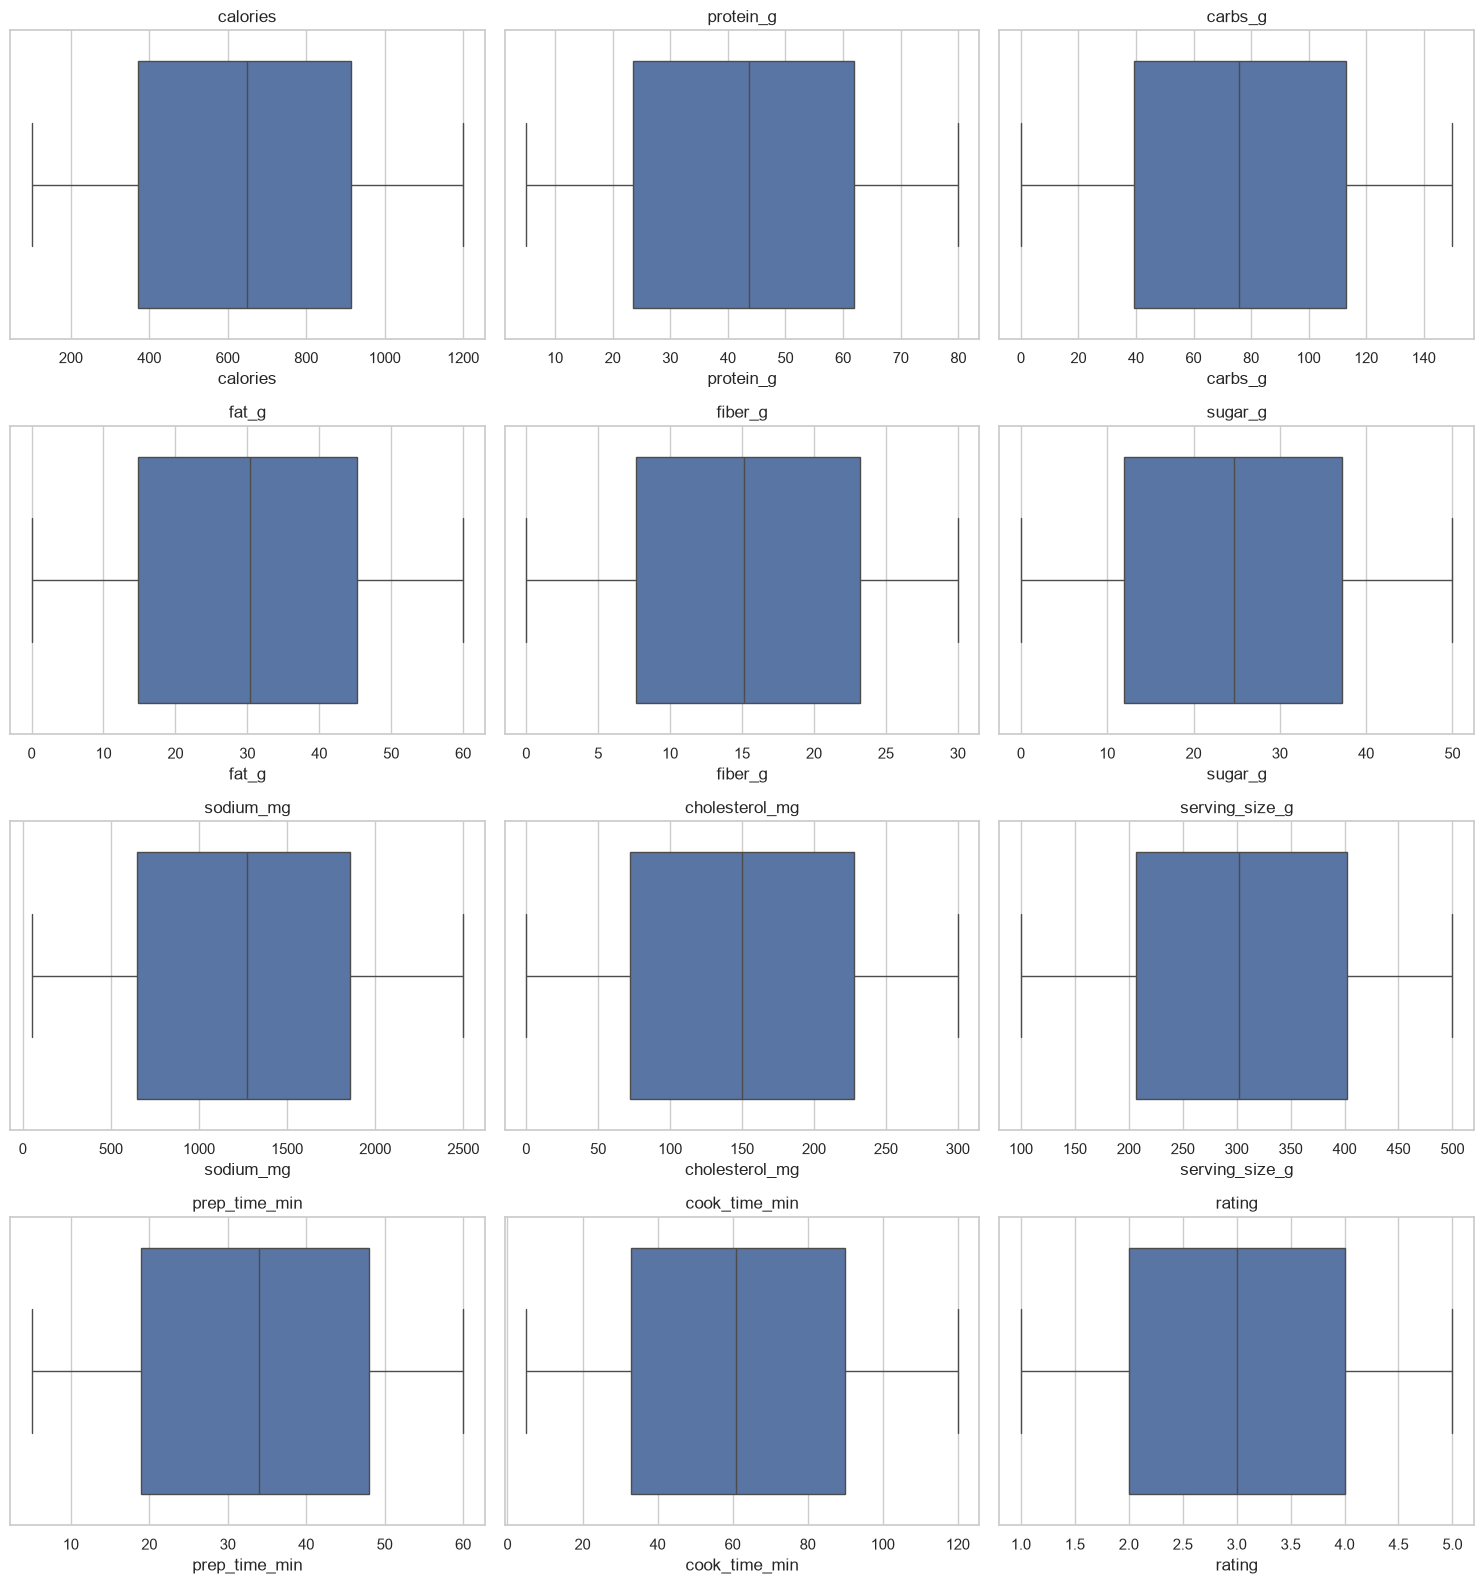

,Нижняя граница,Верхняя граница,Число выбросов,Доля
Признак,,,,
calories,-441.750,1728.250,0,0.0
protein_g,-33.850,119.350,0,0.0
carbs_g,-71.538,223.763,0,0.0
fat_g,-30.800,90.800,0,0.0
fiber_g,-15.800,46.600,0,0.0
sugar_g,-25.800,75.000,0,0.0
sodium_mg,-1163.000,3665.000,0,0.0
cholesterol_mg,-162.000,462.000,0,0.0
serving_size_g,-85.500,694.500,0,0.0


In [7]:
if numeric_cols:
    ncols = 3
    nrows = int(np.ceil(len(numeric_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 4 * nrows))
    axes = np.array(axes).reshape(-1)

    for col, ax in zip(numeric_cols, axes):
        sns.boxplot(x=X[col], ax=ax)
        ax.set_title(col)

    for ax in axes[len(numeric_cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    outlier_rows = []
    for col in numeric_cols:
        q1 = X[col].quantile(0.25)
        q3 = X[col].quantile(0.75)
        iqr = q3 - q1
        lower = q1 - 1.5 * iqr
        upper = q3 + 1.5 * iqr
        count = ((X[col] < lower) | (X[col] > upper)).sum()
        outlier_rows.append([col, lower, upper, int(count), count / len(X)])

    outliers = pd.DataFrame(
        outlier_rows,
        columns=["Признак", "Нижняя граница", "Верхняя граница", "Число выбросов", "Доля"]
    ).set_index("Признак")
    display(outliers.round(3))
else:
    print("Числовых признаков нет.")

**Вывод по выбросам.** IQR помогает обнаружить необычные значения, но не позволяет автоматически объявить их ошибочными. В этой работе потенциальные выбросы сохраняются, если они не являются очевидными ошибками ввода. Это предотвращает потерю реальных наблюдений.

## 5. Обработка пропущенных значений

Проверим наличие пропусков в признаках. В конвейере предобработки предусмотрим замену числовых пропусков медианой, а категориальных — наиболее частым значением. Если пропусков нет, эти шаги не изменят данные. Параметры импутации будут вычисляться только по обучающей выборке.

In [8]:
missing = X.isna().sum()
display(missing[missing > 0].to_frame("Количество пропусков"))

if missing.sum() == 0:
    print("Пропущенных значений в признаках нет.")
else:
    print("Всего пропусков:", int(missing.sum()))

,Количество пропусков


Пропущенных значений в признаках нет.


## 6–7. Кодирование категориальных признаков и нормализация

Категориальные переменные кодируем с помощью One-Hot Encoding. Для каждой категории создаётся отдельный бинарный признак, поэтому категории не получают искусственного числового порядка.

Числовые признаки стандартизируем с помощью `StandardScaler`. Это важно для KNN: иначе переменные с большими числовыми значениями могли бы сильнее влиять на расстояние между объектами. Все преобразования объединяем в `Pipeline` и `ColumnTransformer`, чтобы избежать утечки данных при кросс-валидации.

In [9]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

transformers = []
if numeric_features:
    transformers.append(("num", numeric_transformer, numeric_features))
if categorical_features:
    transformers.append(("cat", categorical_transformer, categorical_features))

preprocessor = ColumnTransformer(transformers=transformers)

print("Числовые признаки:", numeric_features)
print("Категориальные признаки:", categorical_features)

Числовые признаки: ['calories', 'protein_g', 'carbs_g', 'fat_g', 'fiber_g', 'sugar_g', 'sodium_mg', 'cholesterol_mg', 'serving_size_g', 'prep_time_min', 'cook_time_min', 'rating']
Категориальные признаки: ['cuisine', 'meal_type', 'diet_type', 'cooking_method']


## 8. Обучение KNN и подбор оптимального числа соседей

Подберём число соседей `k`, способ взвешивания соседей и метрику расстояния. Используем стратифицированную 5-блочную кросс-валидацию. Основная метрика подбора — F1-score, поскольку она учитывает одновременно Precision и Recall положительного класса.

Тестовая выборка не используется при подборе гиперпараметров.

In [10]:
knn_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", KNeighborsClassifier())
])

param_grid = {
    "classifier__n_neighbors": list(range(1, 32, 2)),
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1, 2]  # 1 — Manhattan, 2 — Euclidean
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

knn_search = GridSearchCV(
    knn_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

knn_search.fit(X_train, y_train)
best_knn = knn_search.best_estimator_

print("Лучшие параметры:", knn_search.best_params_)
print(f"Лучший средний F1-score на кросс-валидации: {knn_search.best_score_:.3f}")

Лучшие параметры: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform'}
Лучший средний F1-score на кросс-валидации: 0.550


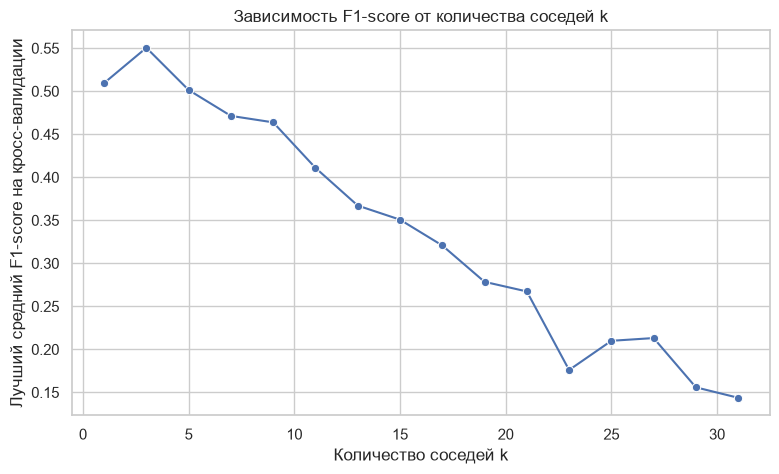

In [11]:
cv_results = pd.DataFrame(knn_search.cv_results_)
by_k = (
    cv_results.groupby("param_classifier__n_neighbors")["mean_test_score"]
    .max()
    .reset_index()
)
by_k["param_classifier__n_neighbors"] = by_k["param_classifier__n_neighbors"].astype(int)

plt.figure(figsize=(9, 5))
sns.lineplot(data=by_k, x="param_classifier__n_neighbors", y="mean_test_score", marker="o")
plt.title("Зависимость F1-score от количества соседей k")
plt.xlabel("Количество соседей k")
plt.ylabel("Лучший средний F1-score на кросс-валидации")
plt.show()

## 9. Ошибки на обучающей и тестовой выборках. Матрицы ошибок

Рассчитаем Accuracy, Precision, Recall и F1-score. Матрица ошибок показывает число верных и ошибочных предсказаний для каждого класса. Особое внимание уделим FN — здоровым блюдам, которые модель ошибочно отнесла к классу 0.

--- KNN — обучающая выборка ---
Accuracy : 0.961
Precision: 0.872
Recall   : 0.679
F1-score : 0.763

Отчёт по классам:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      1360
           1       0.87      0.68      0.76       140

    accuracy                           0.96      1500
   macro avg       0.92      0.83      0.87      1500
weighted avg       0.96      0.96      0.96      1500



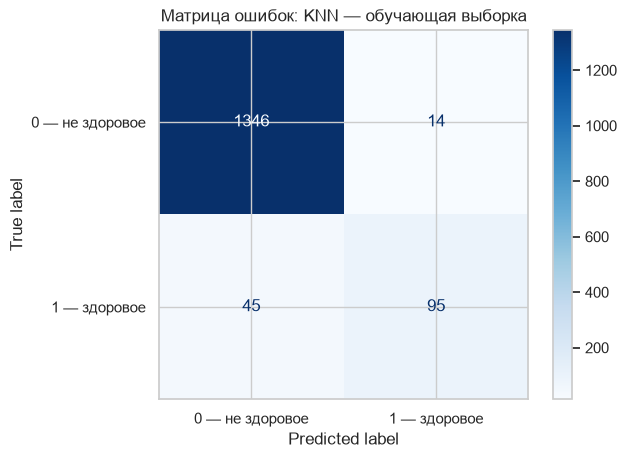

--- KNN — тестовая выборка ---
Accuracy : 0.918
Precision: 0.625
Recall   : 0.319
F1-score : 0.423

Отчёт по классам:
              precision    recall  f1-score   support

           0       0.93      0.98      0.96       453
           1       0.62      0.32      0.42        47

    accuracy                           0.92       500
   macro avg       0.78      0.65      0.69       500
weighted avg       0.90      0.92      0.91       500



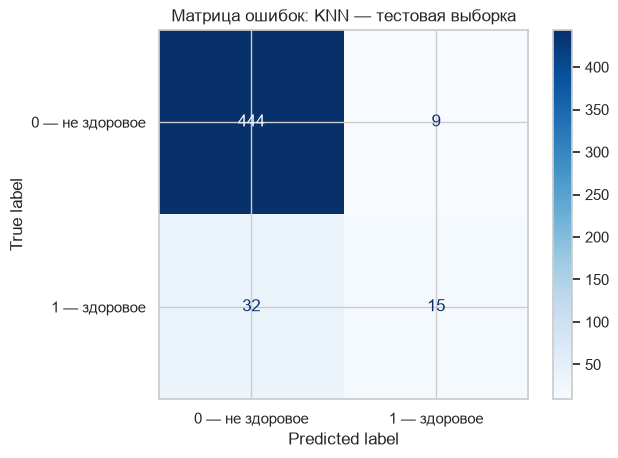

In [12]:
def evaluate_model(model, X_part, y_part, title):
    predictions = model.predict(X_part)

    print(f"--- {title} ---")
    print(f"Accuracy : {accuracy_score(y_part, predictions):.3f}")
    print(f"Precision: {precision_score(y_part, predictions, zero_division=0):.3f}")
    print(f"Recall   : {recall_score(y_part, predictions, zero_division=0):.3f}")
    print(f"F1-score : {f1_score(y_part, predictions, zero_division=0):.3f}")
    print("\nОтчёт по классам:")
    print(classification_report(y_part, predictions, zero_division=0))

    cm = confusion_matrix(y_part, predictions, labels=[0, 1])
    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["0 — не здоровое", "1 — здоровое"]
    ).plot(cmap="Blues", values_format="d")
    plt.title(f"Матрица ошибок: {title}")
    plt.show()

    return predictions

knn_train_pred = evaluate_model(best_knn, X_train, y_train, "KNN — обучающая выборка")
knn_test_pred = evaluate_model(best_knn, X_test, y_test, "KNN — тестовая выборка")

### Комментарий к результатам

Если метрики на обучающей выборке заметно выше тестовых, модель может переобучаться. Если Accuracy высокая, но Recall класса 1 низкий, модель пропускает значительную долю здоровых блюд. Поэтому нельзя оценивать качество только по Accuracy.

## 10. Сравнение с другими классификаторами

Дополнительно обучим DummyClassifier (простейший базовый алгоритм), логистическую регрессию и случайный лес. Для логистической регрессии и случайного леса используем балансировку весов классов, чтобы уменьшить влияние возможного дисбаланса.

In [13]:
models = {
    "Dummy (most frequent)": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", DummyClassifier(strategy="most_frequent"))
    ]),
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced_subsample",
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1
        ))
    ])
}

all_models = {"KNN (best)": best_knn, **models}
comparison_rows = []

for name, model in all_models.items():
    if name != "KNN (best)":
        model.fit(X_train, y_train)

    pred_train = model.predict(X_train)
    pred_test = model.predict(X_test)

    comparison_rows.append({
        "Модель": name,
        "Train Accuracy": accuracy_score(y_train, pred_train),
        "Test Accuracy": accuracy_score(y_test, pred_test),
        "Test Precision": precision_score(y_test, pred_test, zero_division=0),
        "Test Recall": recall_score(y_test, pred_test, zero_division=0),
        "Test F1": f1_score(y_test, pred_test, zero_division=0)
    })

comparison = pd.DataFrame(comparison_rows).sort_values("Test F1", ascending=False)
display(comparison.round(3))

,Модель,Train Accuracy,Test Accuracy,Test Precision,Test Recall,Test F1
3,Random Forest,1.000,0.994,1.000,0.936,0.967
2,Logistic Regression,0.915,0.900,0.482,0.851,0.615
0,KNN (best),0.961,0.918,0.625,0.319,0.423
1,Dummy (most frequent),0.907,0.906,0.000,0.000,0.000


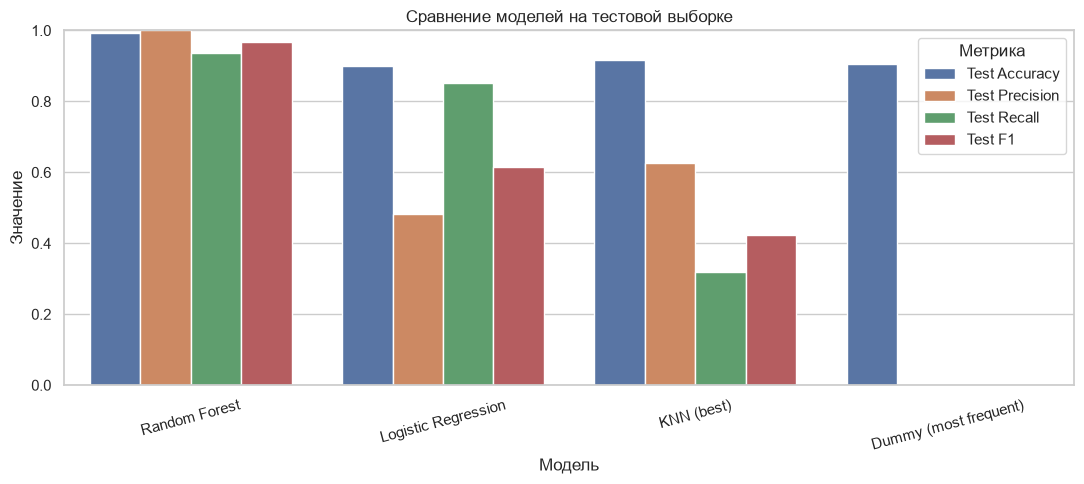

In [14]:
plot_data = comparison.melt(
    id_vars="Модель",
    value_vars=["Test Accuracy", "Test Precision", "Test Recall", "Test F1"],
    var_name="Метрика",
    value_name="Значение"
)

plt.figure(figsize=(11, 5))
sns.barplot(data=plot_data, x="Модель", y="Значение", hue="Метрика")
plt.ylim(0, 1)
plt.title("Сравнение моделей на тестовой выборке")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

## 11. Несбалансированность классов

Распределение классов было рассмотрено в разделе 3. При дисбалансе Accuracy может быть обманчивой. В этой работе используются:
- стратифицированное разделение на обучающую и тестовую выборки;
- подбор KNN по F1-score;
- `class_weight="balanced"` для логистической регрессии;
- `class_weight="balanced_subsample"` для случайного леса;
- DummyClassifier как базовый ориентир.


## 12. Коррелированные переменные

Сильно коррелированные признаки могут частично дублировать информацию. Для KNN это может привести к тому, что похожая характеристика будет фактически учитываться в расстоянии несколько раз. Однако удалять признаки автоматически не обязательно: решение нужно проверять по качеству на валидации. Найдём пары числовых признаков с абсолютной корреляцией выше 0.8.

In [15]:
if len(numeric_cols) >= 2:
    corr_abs = X[numeric_cols].corr().abs()
    upper = corr_abs.where(np.triu(np.ones(corr_abs.shape), k=1).astype(bool))
    pairs = upper.stack().reset_index()
    pairs.columns = ["Признак 1", "Признак 2", "Абсолютная корреляция"]
    pairs = pairs[pairs["Абсолютная корреляция"] > 0.8].sort_values(
        "Абсолютная корреляция", ascending=False
    )

    if pairs.empty:
        print("Пар с |корреляцией| > 0.8 не обнаружено.")
    else:
        display(pairs)
else:
    print("Недостаточно числовых признаков для анализа корреляций.")

Пар с |корреляцией| > 0.8 не обнаружено.


## 13. Общие выводы

После запуска всех ячеек дополните выводы фактическими значениями из таблиц и графиков:

1. В работе решалась задача бинарной классификации: предсказание `is_healthy` для блюда.
2. По распределению целевой переменной определено, насколько сбалансированы классы.
3. По описательной статистике и графикам изучены средние значения, разброс и распределения признаков.
4. Потенциальные выбросы найдены с помощью правила IQR. Правдоподобные значения не удалялись.
5. Проверено наличие пропусков. Для возможных пропусков предусмотрена импутация внутри Pipeline.
6. Категориальные признаки преобразованы One-Hot Encoding, числовые — стандартизированы.
7. Оптимальные параметры KNN выбраны с помощью GridSearchCV и стратифицированной кросс-валидации по F1-score.
8. По обучающим и тестовым метрикам и матрицам ошибок оценено качество KNN.
9. По таблице сравнения определена наиболее эффективная модель. Её результат необходимо сравнить с DummyClassifier.
10. Результат ограничен качеством и составом исходного датасета: модель выявляет статистические зависимости и не является медицинской оценкой полезности блюда.



## Источники

- [Healthy Eating Dataset — Kaggle](https://www.kaggle.com/datasets/khushikyad001/healthy-eating-dataset)
- [MachineLearningCourse — материалы курса](https://github.com/NikolaiZolotykh/MachineLearningCourse)
- [Scikit-learn — документация](https://scikit-learn.org/stable/)